<a href="https://colab.research.google.com/github/Hans1377/subota/blob/main/AI_Security_Monitor_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Security Monitor — запуск в Google Colab
Последовательно запускайте ячейки сверху вниз (Runtime → Run all).

## 1. Загрузка проекта
Загрузите `ai_security_monitor_done.zip` (значок папки слева → Upload) или выберите файл в ячейке ниже.

In [ ]:
import os, glob
if not glob.glob('ai_security_monitor_done.zip'):
    from google.colab import files
    files.upload()   # выберите ai_security_monitor_done.zip

Saving ai_security_monitor_done.zip to ai_security_monitor_done.zip


In [ ]:
!unzip -q -o ai_security_monitor_done.zip
%cd ai_security_monitor
!pip install -q -r requirements.txt

/content/ai_security_monitor
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 115.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 98.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 135.0 MB/s eta 0:00:00


## 2. Данные
Синтетические сетевые данные и текстовый датасет HTTP-запросов (Normal / SQL Injection / XSS).

In [ ]:
!python scripts/generate_network_data.py
!python scripts/generate_text_data.py

Сетевые данные записаны в /content/ai_security_monitor/data
Записано 4500 строк в /content/ai_security_monitor/data/http_requests.csv
label
SQL Injection    1500
XSS              1500
Normal           1500


## 3. Обучение моделей и оценка

In [ ]:
!python train_all.py

== Модуль 1: сетевой трафик ==
Качество данных: 240 дубликатов, 124 пропусков, 123 inf
Isolation Forest: accuracy=0.748 f1_macro=0.6692 FPR=0.1649
Random Forest: accuracy=0.9897 f1_macro=0.9774 FPR=0.0032
== Модуль 2: HTTP-запросы (NLP) ==
После очистки: 4160 строк, удалено дубликатов: 340
Logistic Regression: accuracy=1.0 f1_macro=1.0 FPR=0.0
Naive Bayes: accuracy=1.0 f1_macro=1.0 FPR=0.0
Метрики сохранены в /content/ai_security_monitor/outputs/reports/metrics.json


In [ ]:
import json, pandas as pd
m = json.load(open('outputs/reports/metrics.json', encoding='utf-8'))
rows = []
for part in ('network', 'nlp'):
    for name, v in m[part].items():
        if isinstance(v, dict) and 'accuracy' in v:
            rows.append({'модуль': part, 'модель': name, 'accuracy': v['accuracy'],
                         'f1_macro': v['f1_macro'], 'FPR': v['false_positive_rate']})
pd.DataFrame(rows)

,модуль,модель,accuracy,f1_macro,FPR
0,network,isolation_forest,0.7480,0.6692,0.1649
1,network,random_forest,0.9897,0.9774,0.0032
2,nlp,logistic_regression,1.0000,1.0000,0.0000
3,nlp,naive_bayes,1.0000,1.0000,0.0000


## 4. Матрицы ошибок

outputs/reports/cm_network_isolation_forest.png


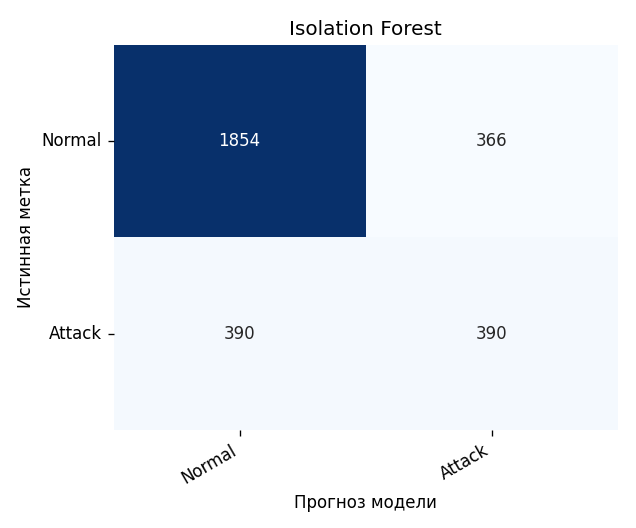

outputs/reports/cm_network_random_forest.png


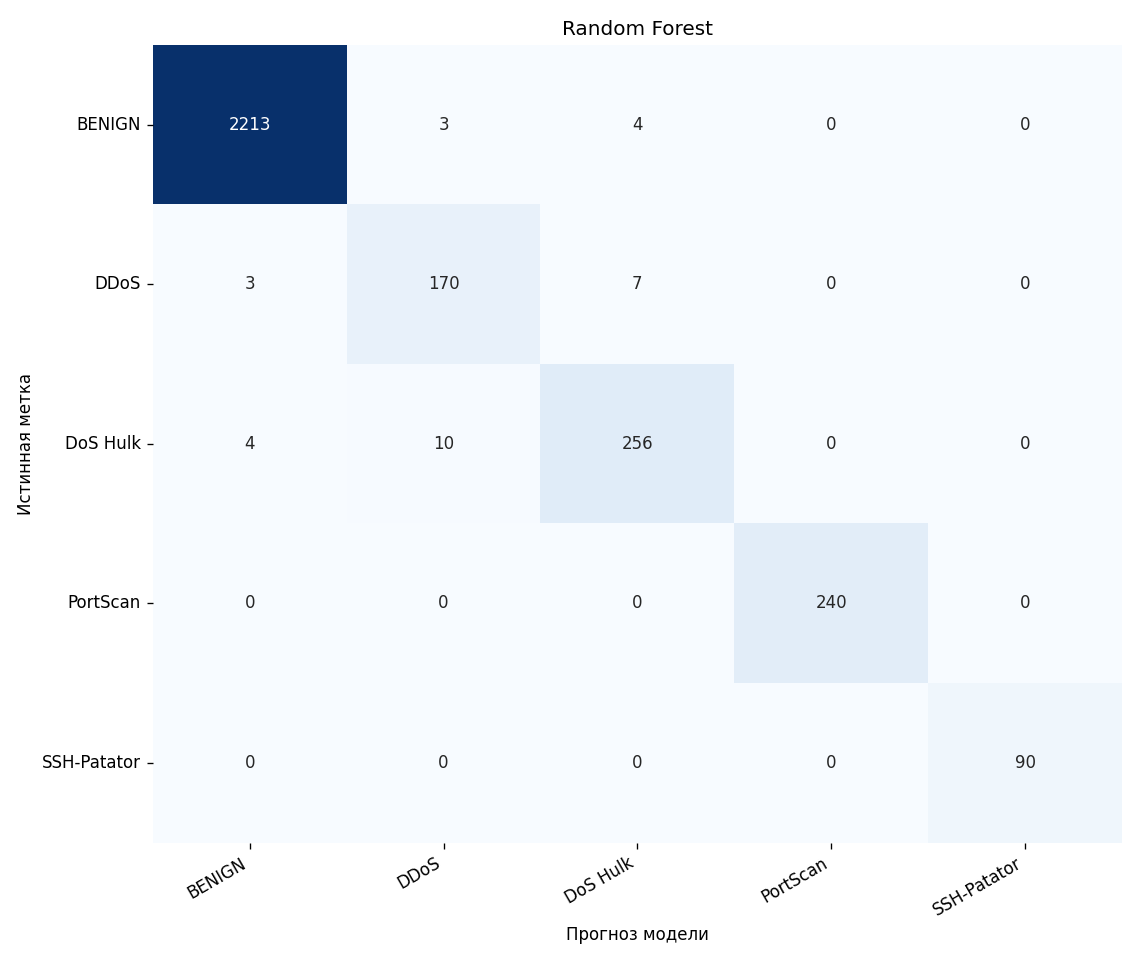

outputs/reports/cm_nlp_logistic_regression.png


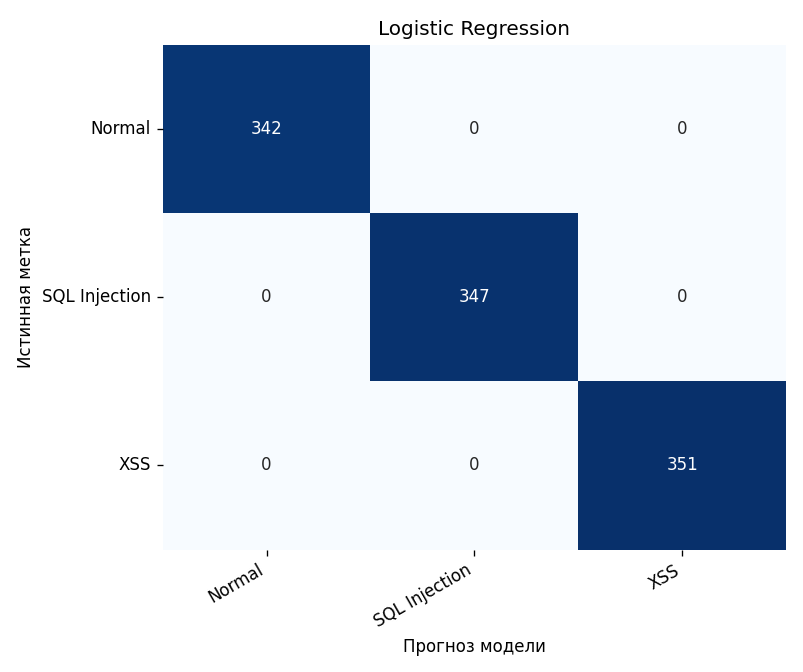

outputs/reports/cm_nlp_naive_bayes.png


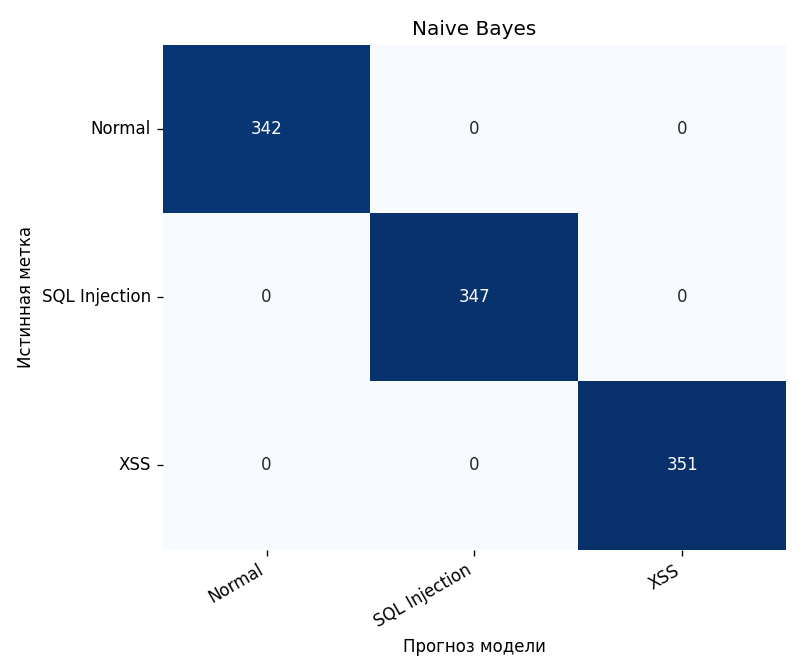

In [ ]:
import glob
from IPython.display import Image, display
for p in sorted(glob.glob('outputs/reports/cm_*.png')):
    print(p); display(Image(p, width=450))

## 5. Ложные срабатывания на «трудных» нормальных запросах

In [ ]:
import joblib, pandas as pd, config
from src.nlp.models import classify_requests
model = joblib.load(config.NLP_MODEL_PATH)
df = pd.read_csv(config.DATA_DIR / 'fp_benign_requests.csv')
res = classify_requests(model, df['request'])
bad = res[res['prediction'] != 'Normal']
display(bad[['request', 'prediction', 'confidence']])
print(f'FPR: {len(bad)}/{len(df)} = {len(bad)/len(df):.0%}')

,request,prediction,confidence
12,/search?q=html+table+example,SQL Injection,0.4978
23,/search?q=where+to+buy+tables+and+chairs,SQL Injection,0.6225


FPR: 2/24 = 8%


## 6. Пример: проверка своего запроса

In [ ]:
tests = ["/search?q=python+book", "/item?id=1' OR '1'='1", "/q?x=<script>alert(1)</script>"]
classify_requests(model, tests)

,request,prediction,confidence,prob_Normal,prob_SQL Injection,prob_XSS,needs_review
0,/search?q=python+book,Normal,0.9174,0.9174,0.0485,0.0341,False
1,/item?id=1' OR '1'='1,SQL Injection,0.9939,0.0035,0.9939,0.0026,False
2,/q?x=<script>alert(1)</script>,XSS,0.9980,0.0010,0.0010,0.9980,False


## 7. Тесты

In [ ]:
!python -m pytest -q

....................                                                     [100%]
20 passed in 34.64s


## 8. Панель Streamlit (через туннель Cloudflare, без регистрации)
После запуска в выводе появится ссылка вида `https://....trycloudflare.com` — откройте её.

In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
import subprocess, time, re
subprocess.Popen(['streamlit','run','app.py','--server.port','8501','--server.headless','true'],
                 stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)
p = subprocess.Popen(['./cloudflared','tunnel','--url','http://localhost:8501'],
                     stderr=subprocess.PIPE, text=True)
for line in p.stderr:
    m = re.search(r'https://[-a-z0-9]+\.trycloudflare\.com', line)
    if m:
        print('Панель:', m.group(0)); break

cloudflared: Text file busy
Панель: https://elegant-introduced-prizes-controversial.trycloudflare.com
